# Cuaderno 04 · Modelo determinístico: formulación, dominio y sensibilidad

**Expediente:** BES-jun · **Estado del expediente:** Listo para revisión (no Completo)

> **Relación con `04_calculos_deterministicos`.** Aquél **verifica el código** (contrato de funciones, reproducción, casos límite, confiabilidad). Éste **formula el modelo como sistema**: qué depende de qué, en qué dominio se ha usado y cuánto pesa cada entrada en el resultado.

## 1. Introducción y contexto (el problema)
Las diez ecuaciones del cuaderno 02 forman una **cadena**: la salida de unas es entrada de otras, hasta producir el caudal a producir \(Q^{*}\). Una cadena es tan frágil como su eslabón más sensible, y ese eslabón no siempre es el más obvio. Si un dato de entrada llega con error (un sensor descalibrado, un diámetro mal transcrito, una TVD desactualizada), ¿cuánto cambia el resultado? ¿Y qué pasa si se usa el modelo fuera del rango en que se ha visto funcionar?

## 2. Justificación y necesidad
Responder tres preguntas con números: (1) **cómo está estructurado** el modelo y si es autoconsistente; (2) **dónde vale**, es decir, qué rango de cada entrada se ha observado y qué hace el código al salir de él; (3) **qué entradas dominan** el resultado, para saber cuáles exigen más cuidado en la calidad del dato. Es la información que permite priorizar controles: no todos los datos merecen la misma vigilancia.

## 3. Objetivo general
Formular el modelo determinístico como sistema, delimitar su dominio de validez observado y cuantificar la sensibilidad local de \(Q^{*}\) a sus entradas, sin predecir ni calibrar.

## 4. Dominio y alcance
**Incluye:** estructura de dependencias; revisión de la autoconsistencia de usar el caudal medido en la fricción; dominio observado y comportamiento fuera de él; elasticidades de \(Q^{*}\) a diez entradas y derivadas respecto de las TVD de los equipos; una figura.

**No incluye:** ajuste de parámetros, incertidumbre real de las entradas (no se conoce), ni validación. Las sensibilidades son **locales** (±1 % alrededor del punto de operación de cada hoja).

## 5. Fuentes y datos (entradas y salidas)
**Entradas:** cinco hojas leídas por rótulo y `analisis.sensibilidad_local` (diferencias centrales recalculando la cadena completa). **Salidas:** tablas y una figura en el cuaderno; ningún archivo escrito.

## 6. Objetivos específicos y criterios de aceptación
**C04b-1** el modelo se reproduce en las 5 hojas antes de perturbarlo (error relativo < 1e-9) · **C04b-2** el método de sensibilidad recupera los exponentes exactos de la fricción · **C04b-3** las elasticidades están definidas en las 5 hojas y 10 entradas (50 valores) · **C04b-4** los signos de THP, TVD de descarga, presión de sensor y frecuencia son los esperados físicamente en las 5 hojas · **C04b-5** cada salida del dominio produce un estado declarado (nunca un error no controlado) · **C04b-6** el libro no cambió.

## 7. Riesgo si este paso falla
Dedicar el control de calidad a las variables equivocadas, o confiar en un resultado extrapolado como si estuviera dentro del dominio conocido.

## Preparación del entorno

In [1]:
from pathlib import Path
import os, sys

def localizar_expediente() -> Path:
    # Sube desde el directorio actual hasta la carpeta que tiene dataset.md y entrada/.
    for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (p / "dataset.md").is_file() and (p / "entrada").is_dir():
            return p
    raise RuntimeError("Ejecute el cuaderno dentro del expediente (donde están dataset.md y entrada/).")

RAIZ = localizar_expediente()                 # .../datasets/en_uso/BES-jun
RAIZ_PROYECTO = RAIZ.parents[2]               # .../HUC
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / "src"))

import pandas as pd
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", lambda v: f"{v:,.8g}")

from analisis.criterios import Criterios
from analisis.entorno import ficha
from analisis.presentacion import T
T(pd.DataFrame(list(ficha().items()), columns=["campo", "valor"]))

campo,valor
fecha_ejecucion,2026-10-20T14:26:02-03:00
python,3.14.8
sistema,Linux 7.2.10-100.fc43.x86_64
pandas,3.0.6
numpy,2.5.4
matplotlib,3.11.2
openpyxl,3.1.5
expediente,BES-jun
insumo,entrada/BES_jun.xlsx
insumo_sha256,ccb5a738baea13321993e8b6eccefd6cac90ecda86b1c4b9181f897fcfa83f85


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from ingesta.integridad import huellas
from ingesta.leer_bes_jun import COPIA_TRABAJO, leer_libro
from analisis.cadena import calcular_hoja
from analisis.sensibilidad_local import ENTRADAS_RELATIVAS, TVD_EQUIPOS, derivada_por_pie, elasticidad_relativa, q_estrella
sha_inicial = huellas(COPIA_TRABAJO)["sha256"]
hojas = leer_libro()
cache = {h["hoja"]: h["cache_caudal_producir_bfpd"] for h in hojas}
q0 = {h["hoja"]: q_estrella(h) for h in hojas}
base = pd.DataFrame([{"hoja": n, "Q* calculado (BFPD)": q0[n], "Q* en la hoja (BFPD)": cache[n], "error relativo": abs(q0[n] - cache[n]) / cache[n]} for n in q0])
T(base)

hoja,Q* calculado (BFPD),Q* en la hoja (BFPD),error relativo
QF-554H,10535.167,10535.167,1.7265882e-16
QF-545H,8280.8591,8280.8591,2.1966192e-16
QF-500H,7360.156,7360.156,6.1785016e-16
QF-378HST,7802.6082,7802.6082,1.1656291e-16
QF-549HST,5503.0344,5503.0344,0


**Qué se verificó.** Antes de perturbar el modelo hay que confirmar que **sin perturbar** reproduce la hoja. De lo contrario, las sensibilidades serían las de un modelo distinto del que se quiere estudiar.

## Paso 1 · Formulación: el modelo como cadena de dependencias

Las entradas fluyen en cuatro etapas. En notación de los cuadernos anteriores:

1. **Fluido:** \((\mathrm{API},T,\mathrm{BSW},\rho_w)\to\gamma_{60}\to\gamma_T\to\rho\to G\).
2. **Balance de alturas:** \((P_s,\mathrm{TVD}_i,\mathrm{TVD}_s,G)\to\mathrm{PIP}\); \((\mathrm{THP},G)\to\mathrm{THP}_{ft}\); \((Q_{op},\mathrm{ID},\mathrm{TVD}_d)\to h_f\); \((\mathrm{TVD}_d,h_f,\mathrm{THP}_{ft},\mathrm{PIP})\to\mathrm{THD}\).
3. **Bomba:** \((\text{curva}_{60},f,f_c,N)\to H'(Q)\).
4. **Intersección:** \(\mathrm{THD}=H'(Q^{*})\to Q^{*}\).

**Observación estructural clave.** La THD depende del caudal por la fricción \(h_f(Q_{op})\), pero en la hoja ese caudal es el **medido** \(Q_{op}\) y no el caudal resultante \(Q^{*}\). Un modelo **autoconsistente** evaluaría la fricción con el propio \(Q^{*}\), es decir, resolvería \(Q^{*}=g(Q^{*})\). La hoja no lo hace: calcula la fricción con el caudal medido y luego intersecta una sola vez. No es un error (puede ser una decisión de diseño de la hoja), pero tiene una consecuencia que conviene cuantificar: **una diferencia entre \(Q^{*}\) y \(Q_{op}\) no es, por sí sola, un error del modelo.**

## Paso 2 · ¿Cuánto cambia el resultado si se hace autoconsistente?

**Qué se hace.** Como **diagnóstico** (no como cálculo de la hoja), se itera: se parte de \(Q_0=Q_{op}\), se calcula \(Q^{*}\) con la fricción evaluada en \(Q_k\), y se repite con \(Q_{k+1}=Q^{*}\) hasta que el cambio sea menor que 0.01 BFPD. Si la iteración converge, el punto fijo es la solución autoconsistente; la diferencia con el \(Q^{*}\) de la hoja mide **cuánto de la brecha calculado-medido se debe a la falta de autoconsistencia**. Es una hipótesis de trabajo, no una corrección.

In [3]:
def punto_fijo(h, tol=0.01, maximo=100):
    q = h["caudal_operacion_bfpd"]
    for k in range(1, maximo + 1):
        nuevo = q_estrella({**h, "caudal_operacion_bfpd": q})
        if nuevo is None:
            return None, k, False
        if abs(nuevo - q) < tol:
            return nuevo, k, True
        q = nuevo
    return q, maximo, False
filas = []
for h in hojas:
    qf, it, conv = punto_fijo(h)
    medido, hoja_q = h["caudal_operacion_bfpd"], q0[h["hoja"]]
    filas.append({"hoja": h["hoja"], "Q medido": medido, "Q* de la hoja": hoja_q, "Q* autoconsistente": qf, "iteraciones": it, "converge": conv,
                  "(hoja − medido)": hoja_q - medido, "(autoconsistente − medido)": qf - medido, "cambio por autoconsistencia": qf - hoja_q})
autoc = pd.DataFrame(filas)
T(autoc, ancha=True)

hoja,Q medido,Q* de la hoja,Q* autoconsistente,iteraciones,converge,(hoja − medido),(autoconsistente − medido),cambio por autoconsistencia
QF-554H,10301,10535.167,10487.206,12,sí,234.16659,186.2059,-47.960685
QF-545H,8767,8280.8591,8413.9814,12,sí,-486.14086,-353.01856,133.1223
QF-500H,7728,7360.156,7512.9067,16,sí,-367.84404,-215.09325,152.75079
QF-378HST,7116,7802.6082,7658.4963,10,sí,686.60822,542.49634,-144.11188
QF-549HST,5419,5503.0344,5470.5996,21,sí,84.034359,51.59962,-32.434739


**Interpretación.** La iteración **converge** en las cinco hojas (10 a 21 pasos). En todas, el punto fijo queda **más cerca del caudal medido** que el \(Q^{*}\) de la hoja: la brecha pasa de 234 a 186 BFPD en `QF-554H`, de 486 a 353 en `QF-545H`, de 368 a 215 en `QF-500H`, de 687 a 542 en `QF-378HST` y de 84 a 52 en `QF-549HST`; es decir, entre un 20 % y un 42 % menos. El sentido es el esperable: si \(Q^{*}\) es mayor que el medido, evaluar la fricción con ese caudal mayor sube la THD y baja \(Q^{*}\), y al revés. **Lo que esto sí dice:** una parte de la diferencia calculado-medido que mostró el cuaderno 05 es un efecto de **cómo está armada la hoja** (fricción con el caudal medido), no un error en las ecuaciones. **Lo que no dice:** que la versión autoconsistente sea la correcta ni que valide el modelo; la brecha restante (52 a 542 BFPD) sigue sin explicar, y esta variante **no es la fórmula de la hoja**, por lo que no se usa en ningún resultado del expediente. Con n = 5 es un diagnóstico, no una conclusión.

## Paso 3 · Dominio de validez: dónde se ha visto funcionar el modelo

**Qué se hace.** Para cada entrada se tabula el **rango observado** en las cinco hojas. Ese rango es el único dominio en el que existe evidencia (reproducción de la hoja). Fuera de él, cada salida del modelo es una **extrapolación**.

In [4]:
ETIQ = {"api_deg": "°API", "temperatura_c": "Temperatura (°C)", "bsw_numero": "BS&W (número)", "presion_sensor_psi": "Presión del sensor (psi)", "thp_psi": "THP (psi)",
        "caudal_operacion_bfpd": "Caudal de operación (BFPD)", "id_tubing_in": "ID del tubing (in)", "tvd_descarga_ft": "TVD descarga (ft)", "frecuencia_hz": "Frecuencia (Hz)", "etapas": "Etapas"}
dom = pd.DataFrame([{"entrada": ETIQ[k], "mínimo observado": min(h[k] for h in hojas), "máximo observado": max(h[k] for h in hojas),
                     "valores distintos": len({h[k] for h in hojas}), "¿hay variación observada?": len({h[k] for h in hojas}) > 1} for k in ENTRADAS_RELATIVAS])
T(dom, ancha=True)

entrada,mínimo observado,máximo observado,valores distintos,¿hay variación observada?
°API,12,12,1,no
Temperatura (°C),62.222222,65.555556,2,sí
BS&W (número),0.9557,0.9766,4,sí
Presión del sensor (psi),607,821,5,sí
THP (psi),145,210,5,sí
Caudal de operación (BFPD),5419,10301,5,sí
ID del tubing (in),2.996,2.996,1,no
TVD descarga (ft),2527.362,2763.6426,5,sí
Frecuencia (Hz),56,67,5,sí
Etapas,31,53,4,sí


**Interpretación.** Dos entradas, el °API (12) y el diámetro interior (2.996 in), tienen **un solo valor observado**; la temperatura tiene dos y el BS&W cuatro. Para esas variables el expediente no tiene evidencia de cómo responde el modelo a un valor distinto; solo se puede estudiar su efecto de forma local (siguiente paso). Las demás tienen rango: frecuencia 56–67 Hz, caudal 5 419–10 301 BFPD, presión del sensor 607–821 psi, THP 145–210 psi, TVD de descarga 2 527–2 764 ft y 31 a 53 etapas. **Cuidado con la noción de «dominio»:** son cinco puntos en un espacio de varias dimensiones; el rango de cada variable por separado es una *caja* que contiene combinaciones de valores nunca observadas juntas. Estar dentro de la caja no implica estar dentro de lo conocido.

### ¿Qué hace el código al salir del dominio?

Se fuerzan, sobre la hoja `QF-554H`, seis entradas fuera del rango observado y se registra el **estado** que devuelve la cadena. Lo que interesa es comprobar que el modelo **nunca falla de forma no controlada**: o calcula, o declara que no puede, o avisa.

In [5]:
h0 = hojas[0]
casos = [("Caudal 2 × el máximo observado", {"caudal_operacion_bfpd": 20000.0}), ("Frecuencia 80 Hz (fuera de 56–67)", {"frecuencia_hz": 80.0}),
         ("Frecuencia 30 Hz", {"frecuencia_hz": 30.0}), ("THP 3 000 psi", {"thp_psi": 3000.0}),
         ("ID del tubing 1.0 in", {"id_tubing_in": 1.0}), ("Presión de sensor ausente", {"presion_sensor_psi": None})]
filas = []
for nombre, cambio in casos:
    try:
        r = calcular_hoja({**h0, **cambio})
        q = r["q"]
        filas.append({"caso": nombre, "estado fluido": r["fl"].estado, "estado balance": r["ba"].estado, "estado intersección": q.estado,
                      "Q* (BFPD)": q.resultados.get("caudal_a_producir_bfpd", {}).get("valor"), "alertas": ", ".join(a if isinstance(a, str) else str(a.get("codigo", a)) for a in q.alertas) or "—",
                      "error no controlado": False})
    except Exception as e:                       # una excepción aquí sería un defecto del código
        filas.append({"caso": nombre, "error no controlado": True, "alertas": f"{type(e).__name__}: {e}"})
fuera = pd.DataFrame(filas)
T(fuera, ancha=True)

caso,estado fluido,estado balance,estado intersección,Q* (BFPD),alertas,error no controlado
Caudal 2 × el máximo observado,calculable,calculable,no_calculable,—,fuera_de_curva_superior,no
Frecuencia 80 Hz (fuera de 56–67),calculable,calculable,calculable,15114.152,—,no
Frecuencia 30 Hz,calculable,calculable,no_calculable,—,fuera_de_curva_superior,no
THP 3 000 psi,calculable,calculable,no_calculable,—,fuera_de_curva_superior,no
ID del tubing 1.0 in,calculable,calculable,no_calculable,—,fuera_de_curva_superior,no
Presión de sensor ausente,calculable,no_calculable,no_calculable,—,dato_faltante,no


**Interpretación.** Ningún caso produjo una excepción: el código **se comporta de forma controlada**. Cuatro de los seis casos terminan en `no_calculable` con la alerta `fuera_de_curva_superior` (la THD exigida supera la altura máxima que la curva de la bomba puede dar: caudal doble, frecuencia de 30 Hz, THP de 3 000 psi y tubing de 1 in); el caso de presión de sensor ausente devuelve `dato_faltante`. **El sexto caso es la advertencia importante:** con 80 Hz, fuera del rango observado (56–67 Hz), la cadena **calcula un caudal de 15 114 BFPD y no emite ninguna alerta**. El código protege contra lo físicamente imposible dentro de la curva y contra los datos ausentes, pero **no avisa de extrapolación respecto del dominio observado**. No se modifica el código (el objetivo de este cuaderno es medir, no cambiar la lógica); queda como pendiente documentado: cualquier uso futuro de estas funciones debe comprobar el dominio observado antes de confiar en un resultado.

## Paso 4 · Sensibilidad local: elasticidades

**Qué es una elasticidad.** Es el cambio porcentual del resultado por cada 1 % de cambio de una entrada: \(\varepsilon_x=\dfrac{\Delta Q^{*}/Q^{*}}{\Delta x/x}\). Si \(\varepsilon=-0.3\), un +1 % en la entrada baja \(Q^{*}\) un 0.3 %. Se calcula por **diferencias centrales** (+1 % y −1 %), **recalculando toda la cadena** con las funciones del contrato; no se usa ninguna fórmula nueva. Como el método es el que da validez a la tabla, el criterio `C04b-2` comprueba que, aplicado a la fricción, recupera sus exponentes exactos (1.85 y −4.8566).

**Cómo leerla.** Es una medida de **cuánto pesa** una entrada, no de cuánto se equivoca: para saber el error del resultado haría falta la incertidumbre real de cada entrada, que no se conoce. Sirve para decidir **dónde poner la atención**.

In [6]:
filas = []
for h in hojas:
    for k in ENTRADAS_RELATIVAS:
        e = elasticidad_relativa(h, k)
        filas.append({"hoja": h["hoja"], "entrada": ETIQ[k], "elasticidad": e["elasticidad"], "ΔQ* por +1 % (BFPD)": e["dq_por_mas_1pct_bfpd"]})
sens = pd.DataFrame(filas)
ela = sens.pivot(index="entrada", columns="hoja", values="elasticidad")[[h["hoja"] for h in hojas]]
ela["|ε| medio"] = ela.abs().mean(axis=1)
ela = ela.sort_values("|ε| medio", ascending=False)
T(ela.reset_index(), ancha=True)

entrada,QF-554H,QF-545H,QF-500H,QF-378HST,QF-549HST,|ε| medio
Frecuencia (Hz),1.8140011,2.6712002,4.1920633,2.0490376,6.5076662,3.4467937
TVD descarga (ft),-0.63419646,-1.2904584,-3.142806,-1.0370917,-4.2918808,2.0792867
ID del tubing (in),0.67983153,1.0670418,2.2526663,0.61652157,1.6197594,1.2471641
Etapas,0.34584136,0.8356419,1.7573323,0.52454502,2.7539708,1.2434663
Presión del sensor (psi),0.27698195,0.651991,2.1097386,0.61609532,2.127345,1.1564304
Caudal de operación (BFPD),-0.22170924,-0.40619002,-0.93729332,-0.23469081,-0.6165926,0.4832952
THP (psi),-0.069245487,-0.20527453,-0.54326063,-0.11028867,-0.62032959,0.30967978
BS&W (número),-0.0097184919,-0.020003136,-0.081249626,-0.023204786,-0.069137031,0.040662614
°API,0.00041941275,0.00086132365,0.0051536878,0.0018482625,0.0055067682,0.002757891
Temperatura (°C),0.00021006693,0.00041076646,0.0025812744,0.00092572015,0.0027581182,0.0013771892


In [7]:
dq = sens.pivot(index="entrada", columns="hoja", values="ΔQ* por +1 % (BFPD)")[[h["hoja"] for h in hojas]].loc[ela.index]
T(dq.reset_index().rename(columns={"entrada": "ΔQ* (BFPD) por +1 % de la entrada"}), ancha=True)

ΔQ* (BFPD) por +1 % de la entrada,QF-554H,QF-545H,QF-500H,QF-378HST,QF-549HST
Frecuencia (Hz),191.10804,221.19833,308.5424,159.87838,358.11911
TVD descarga (ft),-66.813654,-106.86104,-231.31542,-80.920204,-236.18368
ID del tubing (in),71.621384,88.360232,165.79975,48.104762,89.135915
Etapas,36.434964,69.198328,129.3424,40.928193,151.55196
Presión del sensor (psi),29.180509,53.990457,155.28005,48.071504,117.06852
Caudal de operación (BFPD),-23.357437,-33.636024,-68.98625,-18.312004,-33.931302
THP (psi),-7.2951274,-16.998495,-39.98483,-8.6053926,-34.13695
BS&W (número),-1.0238593,-1.6564315,-5.9800992,-1.8105786,-3.8046346
°API,0.044185831,0.071324998,0.37931946,0.14421268,0.30303935
Temperatura (°C),0.022130901,0.034014992,0.18998582,0.072230317,0.15178019


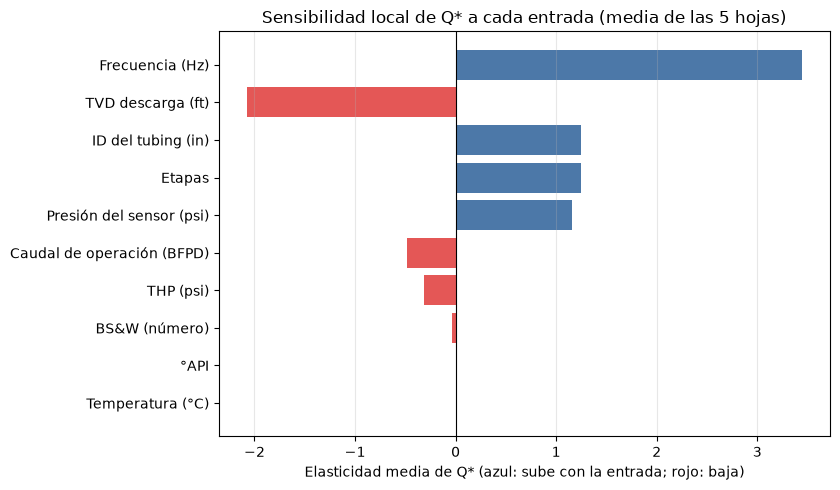

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 5))
orden = ela["|ε| medio"].sort_values()
colores = ["#4c78a8" if ela.loc[k, [h["hoja"] for h in hojas]].mean() > 0 else "#e45756" for k in orden.index]
ax.barh(orden.index, [ela.loc[k, [h["hoja"] for h in hojas]].mean() for k in orden.index], color=colores)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Elasticidad media de Q* (azul: sube con la entrada; rojo: baja)")
ax.set_title("Sensibilidad local de Q* a cada entrada (media de las 5 hojas)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretación de las tablas y de la figura.** **Orden de importancia.** Por elasticidad media absoluta: **frecuencia** (3.4) > **TVD de descarga** (2.1) > **diámetro del tubing** (1.2) ≈ **etapas** (1.2) ≈ **presión del sensor** (1.2) > **caudal de operación** (0.5) > **THP** (0.3) >> **BS&W** (0.04) >> **°API** (0.003) ≈ **temperatura** (0.001). Un 1 % más de frecuencia sube \(Q^{*}\) entre 1.8 % y 6.5 % (160 a 358 BFPD según la hoja). **Lectura física.** La frecuencia y las etapas desplazan la curva de la bomba: pequeños cambios mueven mucho el punto de intersección. La TVD de descarga y el THP aumentan la altura a vencer y bajan el caudal (signo negativo); la presión del sensor la reduce y lo sube; un tubing más ancho reduce la fricción y lo sube. Lo que casi no pesa son las propiedades del fluido: la gravedad del crudo (°API) y la temperatura mueven el resultado menos de 0.4 BFPD por 1 %, porque el fluido es casi agua (BS&W 0.96–0.98). **La sensibilidad no es la misma en todas las hojas:** `QF-500H` y `QF-549HST` son claramente más sensibles que `QF-554H` y `QF-378HST` (por ejemplo, frecuencia 4.2 y 6.5 frente a 1.8 y 2.0), porque en esos pozos la intersección cae en un tramo más plano de la curva (cuaderno 03), que amplifica cualquier cambio. **Cómo usar esto con prudencia:** una elasticidad no es un error. Un 1 % de la presión del sensor son ≈7 psi y mueve \(Q^{*}\) entre 29 y 155 BFPD; un 1 % del diámetro son ≈0.03 in y lo mueve entre 48 y 166 BFPD; un 1 % del THP son ≈2 psi y lo mueve entre 7 y 40 BFPD. Para convertir esto en un error del resultado haría falta la incertidumbre real de cada entrada, que **no está en las fuentes del expediente**. Y las entradas que no varían entre pozos (°API, ID) no pueden estudiarse con datos: solo se conoce su efecto local hipotético.

### Las TVD de los equipos: sensibilidad por pie

Las TVD de intake y sensor son números grandes (≈2 500 ft) cuya **diferencia** (≈20–26 ft) es lo que entra en el PIP: un 1 % de cada una (≈25 ft) es del tamaño de esa separación, de modo que expresarlas en porcentaje no tiene sentido físico. Se expresan por pie.

In [9]:
filas = []
for h in hojas:
    fila = {"hoja": h["hoja"]}
    for k in TVD_EQUIPOS:
        fila[f"dQ*/d{k.replace('_ft', '').upper()} (BFPD por ft)"] = derivada_por_pie(h, k)
    filas.append(fila)
der = pd.DataFrame(filas)
T(der, ancha=True)

hoja,dQ*/dTVD_DESCARGA (BFPD por ft),dQ*/dTVD_INTAKE (BFPD por ft),dQ*/dTVD_SENSOR (BFPD por ft)
QF-554H,-2.205213,-1.7278319,1.7278319
QF-545H,-4.2281652,-3.5087719,3.5087719
QF-500H,-10.378154,-8.9285714,8.9285714
QF-378HST,-2.9280271,-2.569862,2.569862
QF-549HST,-9.0545329,-8.3513862,8.3513862


**Interpretación.** Un error de **1 ft en la TVD de la descarga** mueve \(Q^{*}\) entre −2.2 y −10.4 BFPD según la hoja. Las derivadas respecto de la TVD del intake y del sensor tienen **exactamente la misma magnitud y signo contrario** (por ejemplo ±1.73 BFPD/ft en `QF-554H`), porque en el PIP solo entra su **diferencia**; por eso el error que importa no es el de cada TVD sino el de la **separación** entre ambos equipos: un error de 10 ft en esa separación equivale a entre ≈17 y ≈89 BFPD. Esto refuerza dos controles del cuaderno de calidad: que las TVD de los equipos salgan del survey por interpolación y que se verifique el survey con la curvatura mínima.

## Paso 5 · Criterios de aceptación

In [10]:
from modelo_deterministico.balance_bes_jun import friccion_hazen_williams_ft
crit = Criterios("04_modelo_deterministico")
crit.comprobar("C04b-1", "El modelo se reproduce en las 5 hojas antes de perturbarlo", bool((base["error relativo"] < 1e-9).all()), f"error máx. {base['error relativo'].max():.1e}")
f0 = friccion_hazen_williams_ft(8000.0, 2.996, 2600.0); d = 1e-6
e_q = (friccion_hazen_williams_ft(8000.0 * (1 + d), 2.996, 2600.0) - friccion_hazen_williams_ft(8000.0 * (1 - d), 2.996, 2600.0)) / (2 * d * f0)
e_d = (friccion_hazen_williams_ft(8000.0, 2.996 * (1 + d), 2600.0) - friccion_hazen_williams_ft(8000.0, 2.996 * (1 - d), 2600.0)) / (2 * d * f0)
crit.comprobar("C04b-2", "El método recupera 1.85 y −4.8566 en la fricción", abs(e_q - 1.85) < 1e-6 and abs(e_d + 4.8566) < 1e-5, f"ε_Q = {e_q:.6f}; ε_ID = {e_d:.5f}")
crit.comprobar("C04b-3", "50 elasticidades definidas (5 hojas × 10 entradas)", len(sens) == 50 and bool(sens["elasticidad"].notna().all()), f"{len(sens)} valores")
signos = all(sens[(sens.hoja == h["hoja"])].set_index("entrada").loc[ETIQ[k], "elasticidad"] * s > 0 for h in hojas for k, s in (("thp_psi", -1), ("tvd_descarga_ft", -1), ("presion_sensor_psi", 1), ("frecuencia_hz", 1)))
crit.comprobar("C04b-4", "Signos físicos esperados en las 5 hojas", signos, "THP −, TVD descarga −, P sensor +, frecuencia +")
crit.comprobar("C04b-5", "Cada salida del dominio da un estado declarado", not bool(fuera["error no controlado"].any()), f"{len(fuera)} casos")
crit.comprobar("C04b-6", "El libro no cambió", huellas(COPIA_TRABAJO)["sha256"] == sha_inicial, sha_inicial[:16] + "…")
T(crit.tabla())

id,criterio,resultado,evidencia
C04b-1,El modelo se reproduce en las 5 hojas antes de perturbarlo,CUMPLE,error máx. 6.2e-16
C04b-2,El método recupera 1.85 y −4.8566 en la fricción,CUMPLE,ε_Q = 1.850000; ε_ID = -4.85660
C04b-3,50 elasticidades definidas (5 hojas × 10 entradas),CUMPLE,50 valores
C04b-4,Signos físicos esperados en las 5 hojas,CUMPLE,"THP −, TVD descarga −, P sensor +, frecuencia +"
C04b-5,Cada salida del dominio da un estado declarado,CUMPLE,6 casos
C04b-6,El libro no cambió,CUMPLE,ccb5a738baea1332…


In [11]:
crit.exigir()
print("Todos los criterios de aceptación del cuaderno 04 (modelo) se cumplen.")

Todos los criterios de aceptación del cuaderno 04 (modelo) se cumplen.


## Conclusión técnica

- **Resultado:** el modelo se formuló como cadena de cuatro etapas, se reprodujo antes de perturbarlo y se midió su sensibilidad local a diez entradas y a las TVD de los equipos, con un método validado contra los exponentes exactos de la fricción.
- **Lo que más pesa:** frecuencia, TVD de descarga, diámetro del tubing, etapas y presión del sensor; lo que menos, las propiedades del fluido. La sensibilidad depende del pozo (más alta en `QF-500H` y `QF-549HST`).
- **Hallazgo estructural:** la hoja evalúa la fricción con el caudal medido y no con el resultado; hacerlo autoconsistente reduce la brecha calculado-medido entre 20 % y 42 % (diagnóstico, no corrección).
- **Hallazgo de dominio:** el código controla datos ausentes y alturas fuera de curva, pero no avisa de extrapolación respecto del dominio observado (p. ej. 80 Hz). Queda como pendiente documentado, sin cambiar el código.
- **Qué no se afirma:** que estas sensibilidades sean errores del resultado (falta la incertidumbre de cada entrada) ni que el modelo sea predictivo.
- **Siguiente paso:** `05_evaluacion_por_pozo`, que contrasta los resultados con lo medido y con la ventana operativa.

## Relación con el sistema de reglas

Mide la sensibilidad de Q* y muestra que a 80 Hz, fuera del rango observado, el modelo calcula sin avisar. El evaluador añade esa advertencia en la capa de reglas. No se cambió la ecuación para que el aviso apareciera dentro del modelo.

## Limitaciones

- Las sensibilidades son **locales** (diferencia finita de ±1 % alrededor del punto de operación de cada hoja); no extrapolan a otros puntos.
- No se conoce la incertidumbre real de cada entrada, por lo que las elasticidades indican **cuánto pesa** cada una y no cuánto se equivoca el resultado.
- El dominio de validez es el observado en cinco hojas; salir de él es extrapolar.
- Es un modelo transcrito: no se ajusta ni se calibra.

## Referencias

Solo se listan las fuentes realmente consultadas en este cuaderno.

1. **Libro de trabajo:** `entrada/BES_jun.xlsx`, copia byte a byte de «Copia de FINAL BES-jun.xlsx» (SHA-256 `ccb5a738baea13321993e8b6eccefd6cac90ecda86b1c4b9181f897fcfa83f85`). Cinco hojas: QF-554H, QF-545H, QF-500H, QF-378HST y QF-549HST.
2. **`004-ESPdesign.pdf`** (en la raíz del proyecto): se consultó solo para el exponente de fricción 4.8655 y para el significado de TDH (CT-05).
3. **`docs/consultas_tecnicas_pendientes.md`** (expediente): registro CT-01…CT-10 de ambigüedades abiertas.
4. **Software:** Python 3.14.8, pandas 3.0.6, numpy 2.5.4, matplotlib 3.11.2, openpyxl 3.1.5 (versiones tomadas de la ficha de entorno de cada ejecución).
5. **Métodos de uso general sin cita verificada en las fuentes del expediente:** diferencias finitas centrales para sensibilidad local. Se aplican como están escritos en la hoja o se describen como método estándar, sin atribuirlos a un texto concreto.